# Measuring Ad Incrementality: Criteo Uplift Experiment

## Step 1: Framing the experiment

**Question:** Do ads *cause* more visits and conversions, by how much, and for which users?

Criteo ran a randomized experiment: users were randomly assigned to **treatment** (eligible to be shown ads, ~85%)
or **control** (held out from ads, ~15%). Because assignment is random, any difference in outcomes between the
groups is caused by the ads, not by who the users are.

| | Metric | Why |
|---|---|---|
| **Primary** | `visit` (did the user visit the advertiser's site?) | Common enough (~4.7%) to measure precisely |
| **Secondary** | `conversion` (did the user convert?) | What advertisers ultimately care about, but rare (~0.3%), so noisy |

**Hypothesis:** H₀: visit rate is the same in treatment and control. H₁: the rates differ (two-sided test, α = 0.05).

**Decision this informs:** Should ads be shown broadly, or targeted to the users most likely to be influenced by them?

**Data:** a seeded 10% random sample (`random_state=42`) of the Criteo Uplift Modeling Dataset v2.1
(Diemert et al., AdKDD 2018). Features `f0`–`f11` are anonymized and were measured *before* treatment.

In [1]:
import sys
import warnings
sys.path.append("..")
# scikit-learn 1.4 passes an option newer SciPy no longer recognizes; harmless
warnings.filterwarnings("ignore", message="Unknown solver options")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_criteo, FEATURES
from src import validity

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../figures"

df = load_criteo(frac=0.10, seed=42)
print(f"{len(df):,} users x {df.shape[1]} columns")
df.head()

1,397,959 users x 16 columns


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,exposure,visit,conversion
0,21.2655,10.0597,8.2144,4.6799,10.2805,4.1155,-12.6418,4.8338,3.9719,13.1901,5.3004,-0.1687,0,0,0,0
1,25.7443,10.0597,8.2144,4.6799,10.2805,4.1155,-3.2821,4.8338,3.9719,13.1901,5.3004,-0.1687,1,0,0,0
2,12.6164,10.0597,8.8135,4.6799,10.2805,4.1155,0.2944,4.8338,3.9065,13.1901,5.3004,-0.1687,1,0,0,0
3,12.6164,10.0597,8.8763,4.6799,10.2805,4.1155,0.2944,4.8338,3.8959,13.1901,5.3004,-0.1687,1,0,0,0
4,12.6164,10.0597,9.0071,4.6799,10.2805,4.1155,0.2944,4.8338,3.8901,13.1901,5.3004,-0.1687,1,0,0,0


In [2]:
df[["treatment", "exposure", "visit", "conversion"]].mean().rename("share / rate").to_frame()

,share / rate
treatment,0.8503
exposure,0.0306
visit,0.0473
conversion,0.0030


## Step 2: Validity checks

Before reading any results, we confirm the experiment was run correctly. If randomization broke,
the treatment effect estimate can be biased, and no amount of statistics fixes that.

### 2a. Sample ratio mismatch (SRM)
The experiment intended an 85/15 split. A chi-square goodness-of-fit test asks: *if assignment really were 85/15,
how surprising are the counts we observe?* A very small p-value (common threshold: p < 0.001) would mean users
were lost or duplicated unevenly between arms (logging bugs, bots, redirects), and we should stop and debug.

In [3]:
srm = validity.srm_test(df, expected_treat_share=0.85)
pd.Series(srm).to_frame("value")

,value
n,"1,397,959.0000"
n_treatment,"1,188,739.0000"
n_control,"209,220.0000"
observed_treat_share,0.8503
expected_treat_share,0.8500
chi2,1.2597
p_value,0.2617


### 2b. Covariate balance
If randomization worked, pre-treatment features should look the same in both arms. We use the
**standardized mean difference** (SMD): the difference in means divided by the pooled standard deviation.
With 1.4M users, a t-test would call even trivially small differences "significant", so SMD is the better
measure of whether an imbalance is big enough to matter. Rule of thumb: |SMD| > 0.1 is a concern.

In [4]:
smd = validity.standardized_mean_diff(df, FEATURES)
smd

,feature,mean_treatment,mean_control,smd,imbalanced
0,f0,19.6218,19.6437,-0.0041,False
1,f1,10.0704,10.0677,0.0264,False
2,f2,8.4461,8.4493,-0.0106,False
3,f3,4.1705,4.2342,-0.0491,False
4,f4,10.3395,10.3364,0.0091,False
5,f5,4.0264,4.0388,-0.0297,False
6,f6,-4.1838,-3.9951,-0.0417,False
7,f7,5.1055,5.0831,0.0189,False
8,f8,3.9334,3.9346,-0.0205,False
9,f9,16.0449,15.8911,0.0222,False


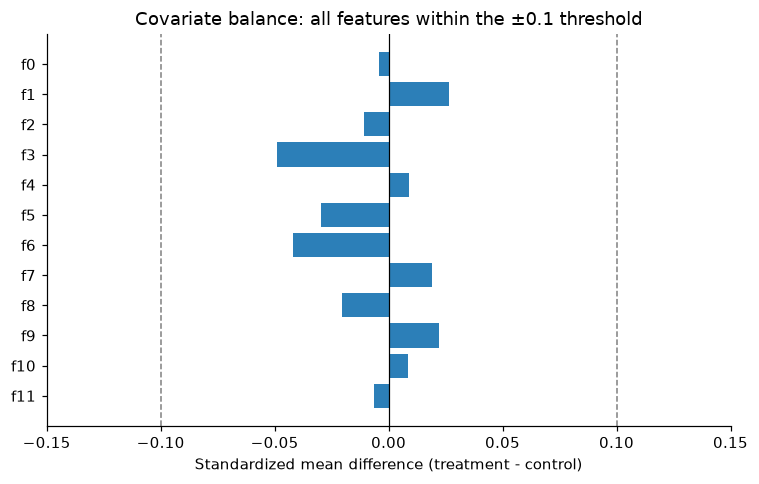

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(smd["feature"], smd["smd"], color=np.where(smd["imbalanced"], "#c0392b", "#2c7fb8"))
for x in (-0.1, 0.1):
    ax.axvline(x, color="grey", ls="--", lw=1)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("Standardized mean difference (treatment - control)")
ax.set_title("Covariate balance: all features within the ±0.1 threshold" if not smd["imbalanced"].any()
             else "Covariate balance: some features exceed ±0.1")
fig.tight_layout()
fig.savefig(f"{FIG}/01_covariate_balance.png", bbox_inches="tight")
plt.show()

### 2c. Exposure check
Being *assigned* to treatment doesn't guarantee seeing an ad (the user may never hit an ad auction Criteo wins).
Control users should **never** be exposed. This is "one-sided non-compliance", which matters later (Step 6) when we
estimate the effect on users who actually saw ads.

In [6]:
validity.exposure_check(df)

,n,n_exposed,exposure_rate
treatment,,,
control,209220,0,0.0000
treatment,1188739,42803,0.0360


In [7]:
exp = validity.exposure_check(df)
print(f"SRM: observed treatment share {srm['observed_treat_share']:.4f} vs 0.85 expected, p = {srm['p_value']:.3g}")
print(f"Balance: max |SMD| = {smd['smd'].abs().max():.4f} ({smd.loc[smd['smd'].abs().idxmax(), 'feature']}); "
      f"{int(smd['imbalanced'].sum())} features over 0.1")
print(f"Exposure: control exposure rate = {exp.loc['control', 'exposure_rate']:.4f} "
      f"({int(exp.loc['control', 'n_exposed'])} exposed control users); "
      f"treatment exposure rate = {exp.loc['treatment', 'exposure_rate']:.4f}")

SRM: observed treatment share 0.8503 vs 0.85 expected, p = 0.262
Balance: max |SMD| = 0.0491 (f3); 0 features over 0.1
Exposure: control exposure rate = 0.0000 (0 exposed control users); treatment exposure rate = 0.0360


## Step 3: Main effect (intent-to-treat)

We compare everyone *assigned* to treatment with everyone *assigned* to control, whether or not they actually saw
an ad. This is the **intent-to-treat (ITT)** effect. It's the effect of the *policy* "show ads to this population",
and it's protected by randomization (comparing only exposed users would not be).

- **Absolute lift** = treatment rate − control rate (in percentage points).
- **Relative lift** = treatment rate / control rate − 1 (how much higher, in %).
- **95% CI (absolute):** two-proportion normal approximation, SE = √(p_T(1−p_T)/n_T + p_C(1−p_C)/n_C).
- **95% CI (relative):** delta method on log(p_T / p_C), which keeps the interval correctly asymmetric.
- **p-value:** two-sided z-test using the pooled SE (the SE you'd expect if H₀ were true).

In [8]:
from src import effects
from src.data import OUTCOMES

itt = effects.lift_table(df, OUTCOMES)
itt_display = pd.DataFrame({
    "control rate": itt["control_rate"].map("{:.3%}".format),
    "treatment rate": itt["treatment_rate"].map("{:.3%}".format),
    "abs. lift (pp)": (itt["abs_lift"] * 100).map("{:+.3f}".format),
    "abs. 95% CI (pp)": [f"[{lo*100:.3f}, {hi*100:.3f}]" for lo, hi in zip(itt["abs_ci_low"], itt["abs_ci_high"])],
    "rel. lift": itt["rel_lift"].map("{:+.1%}".format),
    "rel. 95% CI": [f"[{lo:.1%}, {hi:.1%}]" for lo, hi in zip(itt["rel_ci_low"], itt["rel_ci_high"])],
    "p-value": itt["p_value"].map("{:.2g}".format),
})
itt_display

,control rate,treatment rate,abs. lift (pp),abs. 95% CI (pp),rel. lift,rel. 95% CI,p-value
metric,,,,,,,
visit,3.818%,4.885%,+1.067,"[0.976, 1.157]",+27.9%,"[25.0%, 30.9%]",9.2e-100
conversion,0.196%,0.320%,+0.123,"[0.102, 0.145]",+62.7%,"[47.0%, 80.1%]",2.6e-21


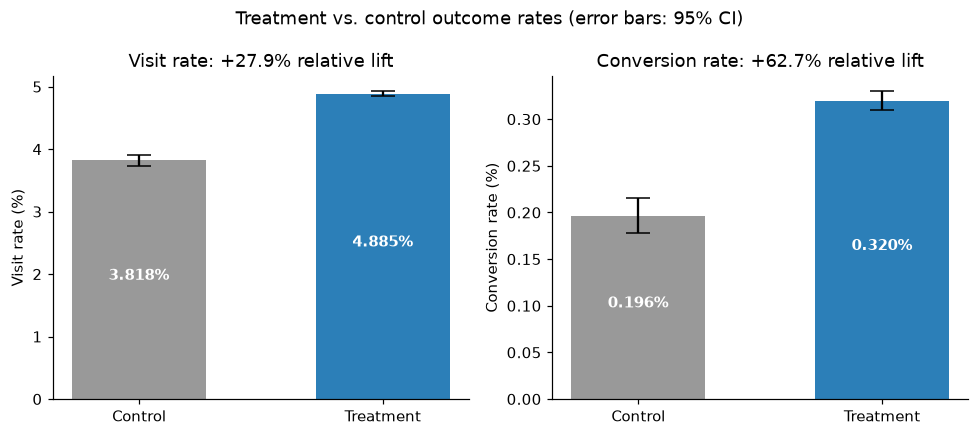

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, metric in zip(axes, OUTCOMES):
    rates = [effects.rate_ci(df.loc[df["treatment"] == t, metric]) for t in (0, 1)]
    p = np.array([r[0] for r in rates]) * 100
    err = np.array([[r[0] - r[1], r[2] - r[0]] for r in rates]).T * 100
    ax.bar(["Control", "Treatment"], p, yerr=err, capsize=8, color=["#999999", "#2c7fb8"], width=0.55)
    for i, v in enumerate(p):
        ax.text(i, v / 2, f"{v:.3f}%", ha="center", color="white", fontweight="bold")
    ax.set_title(f"{metric.capitalize()} rate: {itt.loc[metric, 'rel_lift']:+.1%} relative lift")
    ax.set_ylabel(f"{metric.capitalize()} rate (%)")
fig.suptitle("Treatment vs. control outcome rates (error bars: 95% CI)")
fig.tight_layout()
fig.savefig(f"{FIG}/02_rates_with_ci.png", bbox_inches="tight")
plt.show()

### Bootstrap check
The normal approximation assumes the sampling distribution of the lift is roughly normal. With rare outcomes
(conversion ≈ 0.3%) that's worth checking. The **bootstrap** resamples users with replacement within each arm,
recomputes the lift 1,000 times, and uses the middle 95% of those lifts as the CI, with no normality assumption.

Bootstrapping 1.4M users 1,000 times is slow, so we draw a 200,000-user subsample (keeping the 85/15 split) and
compare the bootstrap CI with the formula CI **on that same subsample**. If they agree there, the formula CIs on the
full data are trustworthy. The subsample CIs are wider than the full-data ones simply because n is smaller.

In [10]:
sub = effects.stratified_subsample(df, n=200_000, seed=42)
formula = effects.lift_table(sub, OUTCOMES)
boot = pd.DataFrame([effects.bootstrap_lift(sub, m, n_boot=1000, seed=42) for m in OUTCOMES]).set_index("metric")

pd.DataFrame({
    "abs. lift (pp)": (formula["abs_lift"] * 100).round(3),
    "formula 95% CI (pp)": [f"[{lo*100:.3f}, {hi*100:.3f}]" for lo, hi in zip(formula["abs_ci_low"], formula["abs_ci_high"])],
    "bootstrap 95% CI (pp)": [f"[{lo*100:.3f}, {hi*100:.3f}]" for lo, hi in zip(boot["abs_ci_low"], boot["abs_ci_high"])],
    "formula rel. CI": [f"[{lo:.1%}, {hi:.1%}]" for lo, hi in zip(formula["rel_ci_low"], formula["rel_ci_high"])],
    "bootstrap rel. CI": [f"[{lo:.1%}, {hi:.1%}]" for lo, hi in zip(boot["rel_ci_low"], boot["rel_ci_high"])],
    "share of resamples with lift <= 0": boot["share_boot_lift_le_0"],
})

,abs. lift (pp),formula 95% CI (pp),bootstrap 95% CI (pp),formula rel. CI,bootstrap rel. CI,share of resamples with lift <= 0
metric,,,,,,
visit,1.0840,"[0.843, 1.324]","[0.849, 1.309]","[20.8%, 36.4%]","[21.2%, 36.4%]",0.0000
conversion,0.1460,"[0.091, 0.201]","[0.092, 0.199]","[36.8%, 139.1%]","[41.8%, 145.2%]",0.0000


In [11]:
for m in OUTCOMES:
    r = itt.loc[m]
    print(f"{m}: {r['control_rate']:.3%} -> {r['treatment_rate']:.3%}; "
          f"abs lift {r['abs_lift']*100:+.3f} pp (95% CI [{r['abs_ci_low']*100:.3f}, {r['abs_ci_high']*100:.3f}]), "
          f"rel lift {r['rel_lift']:+.1%} (95% CI [{r['rel_ci_low']:.1%}, {r['rel_ci_high']:.1%}]), p = {r['p_value']:.2g}")

visit: 3.818% -> 4.885%; abs lift +1.067 pp (95% CI [0.976, 1.157]), rel lift +27.9% (95% CI [25.0%, 30.9%]), p = 9.2e-100
conversion: 0.196% -> 0.320%; abs lift +0.123 pp (95% CI [0.102, 0.145]), rel lift +62.7% (95% CI [47.0%, 80.1%]), p = 2.6e-21


## Step 4: Power and minimum detectable effect (MDE)

**Power** is the probability of detecting an effect if it really exists. The **MDE** is the smallest true effect
we'd detect 80% of the time at α = 0.05 with *this* sample size and split. It answers: "if the test had come back
flat, how big an effect could we have ruled out?" In practice you compute it **before** launching to decide
how long to run the test; here we compute it for the sample we have.

`statsmodels` works in **Cohen's h**, an effect size for proportions: h = 2·arcsin(√p_T) − 2·arcsin(√p_C).
We solve for the smallest detectable h and convert it back to a rate.

In [12]:
n_t, n_c = int(df["treatment"].sum()), int((df["treatment"] == 0).sum())
n_total = n_t + n_c

mde_rows = []
for m in OUTCOMES:
    p_c = itt.loc[m, "control_rate"]
    actual = effects.mde_two_proportions(p_c, n_t, n_c)
    balanced = effects.mde_two_proportions(p_c, n_total // 2, n_total - n_total // 2)
    mde_rows.append({
        "metric": m,
        "control rate": f"{p_c:.3%}",
        "MDE, 85/15 split (pp)": f"{actual['mde_abs']*100:.3f}",
        "MDE, 85/15 split (relative)": f"{actual['mde_rel']:.1%}",
        "MDE if 50/50 split (relative)": f"{balanced['mde_rel']:.1%}",
        "observed rel. lift": f"{itt.loc[m, 'rel_lift']:.1%}",
    })
pd.DataFrame(mde_rows).set_index("metric")

,control rate,"MDE, 85/15 split (pp)","MDE, 85/15 split (relative)",MDE if 50/50 split (relative),observed rel. lift
metric,,,,,
visit,3.818%,0.128,3.4%,2.4%,27.9%
conversion,0.196%,0.031,15.5%,11.0%,62.7%


### Why rare outcomes need much bigger samples
For a binary metric, the variance of each user's outcome is p(1−p). The *absolute* noise shrinks as p falls, but
the *signal* (an x% relative lift = x% × p) shrinks faster, because it's proportional to p while the noise is
proportional to √p. So the signal-to-noise ratio of a relative lift scales like √p, and the sample needed scales
roughly like **1/p**. Conversion is ~20x rarer than visits here, so it needs ~20x more users for the same relative lift:

In [13]:
rows = []
for rel in (0.05, 0.10, 0.20):
    rows.append({"relative lift to detect": f"{rel:.0%}",
                 **{f"users needed ({m})": f"{effects.required_total_n(itt.loc[m, 'control_rate'], rel):,}" for m in OUTCOMES}})
need = pd.DataFrame(rows).set_index("relative lift to detect")
need

,users needed (visit),users needed (conversion)
relative lift to detect,,
5%,"635,022","12,820,407"
10%,"162,400","3,281,742"
20%,"42,387","858,129"


In [14]:
for r in mde_rows:
    print(f"{r['metric']}: MDE = {r['MDE, 85/15 split (pp)']} pp ({r['MDE, 85/15 split (relative)']} relative) "
          f"vs observed {r['observed rel. lift']}; a 50/50 split would give {r['MDE if 50/50 split (relative)']}")
ratio = effects.required_total_n(itt.loc['conversion', 'control_rate'], 0.10) / effects.required_total_n(itt.loc['visit', 'control_rate'], 0.10)
print(f"To detect a 10% relative lift, conversion needs {ratio:.1f}x as many users as visit "
      f"(control-rate ratio = {itt.loc['visit', 'control_rate'] / itt.loc['conversion', 'control_rate']:.1f}x)")

visit: MDE = 0.128 pp (3.4% relative) vs observed 27.9%; a 50/50 split would give 2.4%
conversion: MDE = 0.031 pp (15.5% relative) vs observed 62.7%; a 50/50 split would give 11.0%
To detect a 10% relative lift, conversion needs 20.2x as many users as visit (control-rate ratio = 19.4x)


## Step 5: Variance reduction (CUPED-style regression adjustment)

Much of the variation in who visits has nothing to do with ads: some users are just heavy shoppers. If we explain
that part with **pre-treatment** features, the noise left over is smaller, so the treatment effect is estimated
more precisely. That's the idea behind CUPED (Deng et al., 2013); regression adjustment is the general form.

**Why it doesn't add bias:** the features were measured *before* assignment, so ads can't have changed them.
In a properly randomized test they are independent of treatment, and adjusting for them can only remove noise,
not create a spurious effect. (Adjusting for a *post*-treatment variable, like exposure, would be wrong.)

We fit three linear probability models with robust (HC1) standard errors. HC1 is needed because a binary outcome's
variance, p(1−p), differs across users, which breaks the equal-variance assumption behind classic OLS SEs.
1. `visit ~ treatment`: same as the difference in means from Step 3.
2. `visit ~ treatment + f0 + ... + f11`: the classic adjustment (ANCOVA).
3. `visit ~ treatment * (f0 + ... + f11)` (Lin, 2013): adds treatment × feature interactions. When the ad effect
   varies across users *and* the arms are unequal (85/15), plain ANCOVA's coefficient is a weighted average that
   isn't the population average effect. The interacted version stays consistent for the average effect.

In [15]:
from src import variance

adj = {m: variance.compare_adjustment(df, m, FEATURES) for m in OUTCOMES}

def show_adj(t):
    return pd.DataFrame({
        "effect (pp)": (t["coef"] * 100).map("{:.3f}".format),
        "SE (pp)": (t["se"] * 100).map("{:.4f}".format),
        "95% CI (pp)": [f"[{lo*100:.3f}, {hi*100:.3f}]" for lo, hi in zip(t["ci_low"], t["ci_high"])],
        "relative lift": t["rel_lift"].map("{:.1%}".format),
        "R²": t["r_squared"].map("{:.3f}".format),
        "CI width reduction": t["ci_width_reduction"].map("{:.1%}".format),
        "equiv. sample multiplier": t["equivalent_sample_multiplier"].map("{:.2f}x".format),
    })

show_adj(adj["visit"])

,effect (pp),SE (pp),95% CI (pp),relative lift,R²,CI width reduction,equiv. sample multiplier
unadjusted,1.067,0.0463,"[0.976, 1.157]",27.9%,0.000,0.0%,1.00x
adjusted (ANCOVA),0.736,0.0400,"[0.658, 0.814]",18.0%,0.283,13.7%,1.34x
"adjusted (Lin, interacted)",0.812,0.0415,"[0.730, 0.893]",20.2%,0.284,10.5%,1.25x


In [16]:
show_adj(adj["conversion"])

,effect (pp),SE (pp),95% CI (pp),relative lift,R²,CI width reduction,equiv. sample multiplier
unadjusted,0.123,0.0110,"[0.102, 0.145]",62.7%,0.000,0.0%,1.00x
adjusted (ANCOVA),0.094,0.0103,"[0.074, 0.115]",42.8%,0.122,6.4%,1.14x
"adjusted (Lin, interacted)",0.104,0.0109,"[0.082, 0.125]",49.0%,0.122,0.3%,1.01x


### Precision improved, but the estimate also moved

The features explain ~28% of the variation in visits (R²), and the CI narrows. But the point estimate also dropped,
from 1.07 pp to 0.74–0.81 pp. That shift is many standard errors, so it's not noise. Under clean randomization,
adjustment should mainly shrink the CI and barely move the estimate, so we investigate.

**Diagnostic: prognostic-score balance.** Predict each user's visit probability from features alone, using a model
fit on control users only, then compare the average prediction between arms. This rolls all 12 small feature
imbalances into one number in visit units: *how much more would treatment users visit even without ads?*

In [17]:
prog = validity.prognostic_balance(df, FEATURES, "visit")
z = validity.smd_z_scores(smd, n_t, n_c)
print(f"Predicted visit rate from features alone: treatment {prog['pred_treatment']:.3%} vs control {prog['pred_control']:.3%}")
print(f"Gap = {prog['gap']*100:.3f} pp, z = {prog['z']:.1f} (randomization alone would give |z| < 2 about 95% of the time)")
print(f"Unadjusted effect minus this gap: {(itt.loc['visit', 'abs_lift'] - prog['gap'])*100:.3f} pp "
      f"vs Lin-adjusted {adj['visit'].loc['adjusted (Lin, interacted)', 'coef']*100:.3f} pp")
z.rename("SMD z-score").to_frame().T

Predicted visit rate from features alone: treatment 4.058% vs control 3.818%
Gap = 0.239 pp, z = 10.4 (randomization alone would give |z| < 2 about 95% of the time)
Unadjusted effect minus this gap: 0.827 pp vs Lin-adjusted 0.812 pp


feature,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11
SMD z-score,-1.7174,11.1153,-4.4610,-20.7282,3.8558,-12.5392,-17.6001,7.9525,-8.6658,9.3528,3.5915,-2.6238


**Interpretation.** Each feature's imbalance is small in *practical* terms (all |SMD| < 0.1, which Step 2 checked),
but with 1.4M users several are far outside what chance would produce (|z| ≫ 2). Combined, treatment users look like
heavier visitors before any ads: about +0.24 pp. Subtracting that from the raw 1.07 pp lands right at the Lin estimate.

Criteo's documentation says the dataset was *"constructed by assembling data resulting from several incrementality
tests."* A plausible explanation (we can't verify it, because the test ID isn't in the data) is that the tests had
different populations and treatment ratios, so pooling them makes treatment slightly correlated with user features,
even if each test was randomized on its own. Regression adjustment corrects for exactly this kind of
**observable** imbalance, so here it improves both precision *and* accuracy. Lin's interacted model is the
safest of the three, because ANCOVA's estimate is also affected by effect heterogeneity under the 85/15 split.

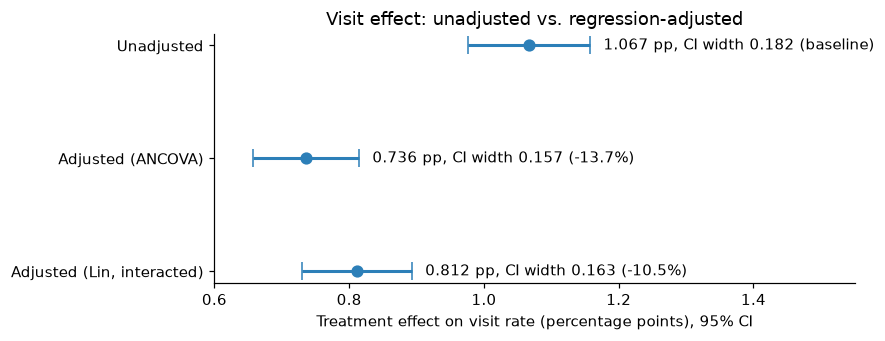

In [18]:
labels = ["Unadjusted", "Adjusted (ANCOVA)", "Adjusted (Lin, interacted)"]
t = adj["visit"]
fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(t))[::-1]
ax.errorbar(t["coef"] * 100, y,
            xerr=[(t["coef"] - t["ci_low"]) * 100, (t["ci_high"] - t["coef"]) * 100],
            fmt="o", capsize=6, color="#2c7fb8", ms=7, lw=2)
for yi, (_, r) in zip(y, t.iterrows()):
    ax.text(r["ci_high"] * 100 + 0.02, yi,
            f"{r['coef']*100:.3f} pp, CI width {r['ci_width']*100:.3f}"
            + (f" ({-r['ci_width_reduction']:+.1%})" if r["ci_width_reduction"] else " (baseline)"), va="center")
ax.set_yticks(y, labels)
ax.set_xlim(0.6, 1.55)
ax.set_xlabel("Treatment effect on visit rate (percentage points), 95% CI")
ax.set_title("Visit effect: unadjusted vs. regression-adjusted")
fig.tight_layout()
fig.savefig(f"{FIG}/03_ci_naive_vs_adjusted.png", bbox_inches="tight")
plt.show()

In [19]:
for m in OUTCOMES:
    u, l = adj[m].loc["unadjusted"], adj[m].loc["adjusted (Lin, interacted)"]
    print(f"{m}: unadjusted {u['coef']*100:.3f} pp [{u['ci_low']*100:.3f}, {u['ci_high']*100:.3f}] -> "
          f"Lin {l['coef']*100:.3f} pp [{l['ci_low']*100:.3f}, {l['ci_high']*100:.3f}], "
          f"relative lift {l['rel_lift']:.1%}; CI width -{l['ci_width_reduction']:.1%}")

visit: unadjusted 1.067 pp [0.976, 1.157] -> Lin 0.812 pp [0.730, 0.893], relative lift 20.2%; CI width -10.5%
conversion: unadjusted 0.123 pp [0.102, 0.145] -> Lin 0.104 pp [0.082, 0.125], relative lift 49.0%; CI width -0.3%


### Robustness: does the adjusted estimate depend on the adjustment method?

Lin's model adjusts *linearly* for each feature. If the imbalance lives in nonlinear pockets (combinations of
feature values, e.g. users from one pooled test), a linear adjustment could miss it. Three checks:

1. **Propensity AUC.** Predict treatment from features with XGBoost, scored out-of-fold (5-fold cross-fitting),
   so each user's score comes from a model that never saw them. AUC = 0.5 means assignment is unpredictable.
2. **IPW** (inverse propensity weighting). Reweight treated users by 1/e(x) and control users by 1/(1−e(x)) so both
   arms match the full population. Fit with a linear (logistic) propensity and with XGBoost, and with trimming of
   extreme propensities. IPW relies entirely on the propensity model, so extreme weights make it noisy.
3. **AIPW (doubly robust).** Combine cross-fitted XGBoost outcome models with the XGBoost propensity. It's consistent
   if *either* model is right, and the outcome model absorbs most of the noise that destabilizes plain IPW.
   This is the tie-breaker.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

e_xgb = variance.cross_fit_propensity(df, FEATURES, n_folds=5, seed=42)
e_logit = pd.Series(LogisticRegression(max_iter=1000)
                    .fit(StandardScaler().fit_transform(df[FEATURES]), df["treatment"])
                    .predict_proba(StandardScaler().fit_transform(df[FEATURES]))[:, 1], index=df.index)

auc_xgb = roc_auc_score(df["treatment"], e_xgb)
auc_logit = roc_auc_score(df["treatment"], e_logit)
print(f"Propensity AUC: XGBoost (out-of-fold) {auc_xgb:.4f}, logistic {auc_logit:.4f}")
print(f"XGBoost propensity range [{e_xgb.min():.3f}, {e_xgb.max():.3f}]; "
      f"{(e_xgb > 0.95).mean():.2%} of users have e(x) > 0.95")

Propensity AUC: XGBoost (out-of-fold) 0.5097, logistic 0.5097
XGBoost propensity range [0.178, 0.996]; 0.18% of users have e(x) > 0.95


In [21]:
robust = {"unadjusted": adj["visit"].loc["unadjusted"].to_dict(),
          "Lin regression adjustment": adj["visit"].loc["adjusted (Lin, interacted)"].to_dict(),
          "IPW, logistic propensity": variance.ipw_effect(df, "visit", e_logit),
          "IPW, XGBoost propensity": variance.ipw_effect(df, "visit", e_xgb)}
for lo, hi in [(0.05, 0.95), (0.10, 0.90)]:
    keep = e_xgb.between(lo, hi, inclusive="neither")
    robust[f"IPW, XGBoost, trimmed to ({lo}, {hi}) [{keep.mean():.1%} kept]"] = variance.ipw_effect(df[keep], "visit", e_xgb[keep])
    robust[f"Lin on that same trimmed set ({lo}, {hi})"] = variance.treatment_ols(df[keep], "visit", FEATURES, interact=True)
robust["AIPW (doubly robust, cross-fit XGBoost)"] = variance.aipw_effect(df, "visit", FEATURES, e_xgb)

rb = pd.DataFrame(robust).T
pd.DataFrame({
    "visit effect (pp)": (rb["coef"] * 100).map("{:.3f}".format),
    "95% CI (pp)": [f"[{lo*100:.3f}, {hi*100:.3f}]" for lo, hi in zip(rb["ci_low"], rb["ci_high"])],
    "relative lift": rb["rel_lift"].map("{:.1%}".format),
    "max IPW weight": rb.get("max_weight").map(lambda x: "" if pd.isna(x) else f"{x:.0f}"),
    "effective n": rb.get("effective_n").map(lambda x: "" if pd.isna(x) else f"{x:,.0f}"),
})

,visit effect (pp),95% CI (pp),relative lift,max IPW weight,effective n
unadjusted,1.067,"[0.976, 1.157]",27.9%,,
Lin regression adjustment,0.812,"[0.730, 0.893]",20.2%,,
"IPW, logistic propensity",0.821,"[0.727, 0.916]",20.5%,13,"710,251"
"IPW, XGBoost propensity",0.628,"[0.521, 0.735]",15.0%,207,"692,210"
"IPW, XGBoost, trimmed to (0.05, 0.95) [99.8% kept]",0.689,"[0.592, 0.787]",16.9%,20,"703,448"
"Lin on that same trimmed set (0.05, 0.95)",0.790,"[0.709, 0.871]",19.8%,,
"IPW, XGBoost, trimmed to (0.1, 0.9) [98.7% kept]",0.646,"[0.555, 0.738]",17.2%,10,"702,516"
"Lin on that same trimmed set (0.1, 0.9)",0.657,"[0.579, 0.736]",17.6%,,
"AIPW (doubly robust, cross-fit XGBoost)",0.777,"[0.692, 0.862]",19.2%,,


**Reading the robustness table.**
- Propensity AUC ≈ 0.51: assignment is *almost* unpredictable from features, consistent with the small (but, at this
  n, statistically real) imbalance found above.
- The linear methods agree: Lin regression and IPW with a logistic propensity land in the same place.
- Plain IPW with an XGBoost propensity comes in lower. XGBoost finds small pockets (well under 1% of users) where
  assignment is near-certain, and those users get very large weights (max weight in the hundreds, effective sample
  size about half of n), which makes plain IPW unstable. Trimming those pockets also changes *who* is averaged over,
  so the trimmed rows should be compared with Lin on the same trimmed set, not with the full-sample estimate.
- The **doubly robust AIPW** estimate, which uses the same XGBoost propensity but stabilizes it with outcome models,
  lands close to Lin, with heavily overlapping CIs. So the Lin estimate is not an artifact of linear adjustment, and
  we keep it as the headline, while reporting the spread across methods as a robustness range.

## Step 6: Non-compliance — ITT vs. the effect on users who actually saw ads (CACE)

Only **3.6%** of treatment users were actually exposed to an ad (Step 2c). The ITT averages the ad effect over all
assigned users, most of whom never saw one, so it **dilutes** the effect per exposed user.

We can't just compare exposed vs. unexposed users: exposure wasn't randomized. Users who get exposed are the ones
who browse a lot, and they'd visit more anyway. Instead we use **assignment as an instrument** for exposure.

**Wald estimator:** CACE = ITT on outcome / ITT on exposure. Intuition: assignment raised exposure by 3.6 pp and visits
by ITT pp; if *all* of the visit increase flows through exposure, the effect per exposed user is the ratio.

This is the **complier average causal effect**: the effect for users who'd be exposed if assigned to treatment.
Here that's the same as the effect on the treated-and-exposed, because no control users could be exposed.

**Assumptions:**
1. **Random assignment:** treatment is independent of potential outcomes. Step 5 showed a small observable
   imbalance, so we also report a covariate-adjusted CACE (Lin-adjusted ITTs in the numerator and denominator).
2. **Exclusion restriction:** assignment affects visits *only* through ad exposure. Plausible: being in the
   treatment group changes nothing else a user sees.
3. **One-sided non-compliance:** no control user is exposed (verified: 0 of 209,220), so there are no "always-takers"
   or "defiers".
4. **Relevance:** assignment actually moves exposure (3.6 pp, a strong first stage at this sample size).

In [22]:
from src import compliance

cace_rows = []
for m in OUTCOMES:
    w = compliance.wald_cace(df, m)
    b = compliance.bootstrap_cace(df, m, n_boot=1000, seed=42)
    a = compliance.adjusted_cace(df, m, FEATURES)
    raw = compliance.complier_means(df, m)
    adjm = compliance.adjusted_complier_means(df, m, FEATURES)
    # Each relative CACE uses a baseline from the *same* model as its CACE
    for label, r, lo, hi, base in [
            ("unadjusted (Wald, bootstrap CI)", w, b["ci_low"], b["ci_high"], raw["compliers_without_ads"]),
            ("Lin-adjusted (IV-linearized CI)", a, a["ci_low"], a["ci_high"], adjm["compliers_without_ads"])]:
        cace_rows.append({"metric": m, "estimator": label,
                          "ITT on outcome (pp)": r["itt_outcome"] * 100,
                          "ITT on exposure (pp)": r["itt_exposure"] * 100,
                          "CACE (pp)": r["cace"] * 100,
                          "CACE 95% CI (pp)": f"[{lo*100:.2f}, {hi*100:.2f}]",
                          "complier no-ad baseline": base,
                          "CACE relative": r["cace"] / base})
cace = pd.DataFrame(cace_rows).set_index(["metric", "estimator"])
cace.style.format({"ITT on outcome (pp)": "{:.3f}", "ITT on exposure (pp)": "{:.2f}", "CACE (pp)": "{:.2f}",
                   "complier no-ad baseline": "{:.2%}", "CACE relative": "{:+.0%}"})

### Who are the compliers? Decomposing outcomes by complier type
Under one-sided non-compliance we can recover the compliers' visit rate *without* ads: control users are a random
mix of compliers and never-takers, and never-takers' rate is observed in treated-but-unexposed users. So
E[Y₀ | complier] = (control rate − (1 − π) × never-taker rate) / π, where π is the complier share.

We compute it two ways:
- **Unadjusted:** raw arm means.
- **Adjusted:** every piece (exposure share, rate among exposed, rate among unexposed, control rate) is a Lin-adjusted
  arm mean evaluated at the same average features. By the linearity of OLS, "with ads − without ads" then equals the
  adjusted CACE exactly, so the baseline and the effect come from one consistent model.

In [23]:
dec = pd.DataFrame({
    ("unadjusted", m): {**compliance.complier_means(df, m), "cace": compliance.wald_cace(df, m)["cace"]} for m in OUTCOMES
} | {
    ("adjusted", m): compliance.adjusted_complier_means(df, m, FEATURES) for m in OUTCOMES
}).T.sort_index(level=1, sort_remaining=False)
dec["cace_relative"] = dec["compliers_with_ads"] / dec["compliers_without_ads"] - 1
pd.DataFrame({
    "complier share π": dec["complier_share"].map("{:.2%}".format),
    "compliers, with ads": dec["compliers_with_ads"].map("{:.2%}".format),
    "compliers, without ads": dec["compliers_without_ads"].map("{:.2%}".format),
    "never-takers": dec["never_takers"].map("{:.2%}".format),
    "CACE (pp)": (dec["cace"].astype(float) * 100).map("{:.2f}".format),
    "CACE relative": dec["cace_relative"].map("{:+.0%}".format),
})

,,complier share π,"compliers, with ads","compliers, without ads",never-takers,CACE (pp),CACE relative
unadjusted,conversion,3.60%,5.59%,2.17%,0.12%,3.42,+158%
adjusted,conversion,3.54%,5.56%,2.64%,0.12%,2.93,+111%
unadjusted,visit,3.60%,41.83%,12.21%,3.50%,29.62,+243%
adjusted,visit,3.54%,41.68%,18.76%,3.48%,22.93,+122%


**Why the two complier baselines differ (≈12% vs ≈19% for visits).** The rate among exposed users barely moves
with adjustment, so almost the whole difference is in the *implied* no-ad baseline, which is a back-calculation.
The unadjusted version uses the raw control rate as the no-ad benchmark for the treatment arm. But Step 5 showed
treatment users are slightly heavier visitors before any ads (+0.24 pp). The decomposition attributes that entire
gap to compliers and divides it by π ≈ 3.6%, which magnifies it about 28x into several points of "effect" per
complier, pushing their implied no-ad rate down to about 12%. Adjustment removes the imbalance first, so the implied
no-ad rate comes out higher (≈19%) and the CACE smaller. The difference between the two CACEs (≈6.7 pp) is roughly
the imbalance divided by π.

**Consistency rule for the memo:** use the **adjusted** version everywhere: the adjusted CACE, its CI, and the adjusted
complier baseline and relative effect, all from this decomposition. Unadjusted figures are shown only as the comparison.

### Why the naive "exposed vs. unexposed" comparison is wrong
Comparing exposed users with unexposed users in the treatment arm mixes the ad effect with who gets exposed:
exposed users are heavy browsers who would visit far more than never-takers even without ads.

In [24]:
v_w = cace.loc[("visit", "unadjusted (Wald, bootstrap CI)")]
v_a = cace.loc[("visit", "Lin-adjusted (IV-linearized CI)")]
d_a, d_u = dec.loc[("adjusted", "visit")], dec.loc[("unadjusted", "visit")]
print(f"Visit ITT {v_a['ITT on outcome (pp)']:.3f} pp / exposure ITT {v_a['ITT on exposure (pp)']:.2f} pp "
      f"-> adjusted CACE {v_a['CACE (pp)']:.2f} pp {v_a['CACE 95% CI (pp)']}: "
      f"compliers {d_a['compliers_without_ads']:.1%} -> {d_a['compliers_with_ads']:.1%} ({d_a['cace_relative']:+.0%}); "
      f"unadjusted {v_w['CACE (pp)']:.2f} pp {v_w['CACE 95% CI (pp)']}")
print(f"Naive exposed-vs-unexposed gap = {d_u['naive_exposed_vs_unexposed']*100:.2f} pp vs adjusted CACE {v_a['CACE (pp)']:.2f} pp; "
      f"never-exposed users visit {d_a['never_takers']:.1%} of the time")
print(f"Unadjusted - adjusted CACE = {(d_u['cace'] - d_a['cace'])*100:.2f} pp; "
      f"imbalance / pi = {prog['gap'] / d_a['complier_share']*100:.2f} pp")

Visit ITT 0.812 pp / exposure ITT 3.54 pp -> adjusted CACE 22.93 pp [20.64, 25.21]: compliers 18.8% -> 41.7% (+122%); unadjusted 29.62 pp [26.87, 32.05]
Naive exposed-vs-unexposed gap = 38.33 pp vs adjusted CACE 22.93 pp; never-exposed users visit 3.5% of the time
Unadjusted - adjusted CACE = 6.70 pp; imbalance / pi = 6.76 pp


## Step 7: Heterogeneous effects — who is most influenced by ads? (uplift modeling)

So far we've estimated *average* effects. But the decision is whether to show ads to everyone or **target** the
users ads actually move. That requires predicting each user's individual effect, their **uplift**.

We can't observe an individual's uplift (each user is either treated or not), so we model it:
- **T-learner:** train one XGBoost classifier on treated users to predict P(visit | x, ads) and another on control
  users to predict P(visit | x, no ads). Predicted uplift = the difference.
- **70/30 split**, stratified by treatment, so evaluation is on users the models never saw.
- **Qini curve:** sort test users by predicted uplift (highest first). At each cutoff, count incremental visits so far:
  treated visits − control visits × (N treated / N control). A good model rises steeply at first (it finds the
  persuadable users early). Random targeting is the straight diagonal.
- **Qini AUC:** area between the model's curve and the diagonal, normalized by the best possible curve's area (0 = random).

In [25]:
from sklift.metrics import qini_auc_score
from sklift.viz import plot_qini_curve
from src import uplift

train, test = uplift.split(df, test_size=0.3, seed=42)
print(f"train {len(train):,} users ({train['treatment'].mean():.2%} treated), "
      f"test {len(test):,} users ({test['treatment'].mean():.2%} treated)")

tl = uplift.TLearner().fit(train[FEATURES], train["visit"], train["treatment"])
test_uplift = tl.predict(test[FEATURES])
pd.Series(test_uplift * 100).describe(percentiles=[.01, .1, .5, .9, .99]).rename("predicted uplift (pp)").to_frame().T

train 978,571 users (85.03% treated), test 419,388 users (85.03% treated)


,count,mean,std,min,1%,10%,50%,90%,99%,max
predicted uplift (pp),"419,388.0000",0.8077,3.1704,-46.0729,-3.4839,-0.0460,0.0570,2.0581,16.0662,62.6469


Qini AUC: T-learner 0.0734 vs random scores -0.0038


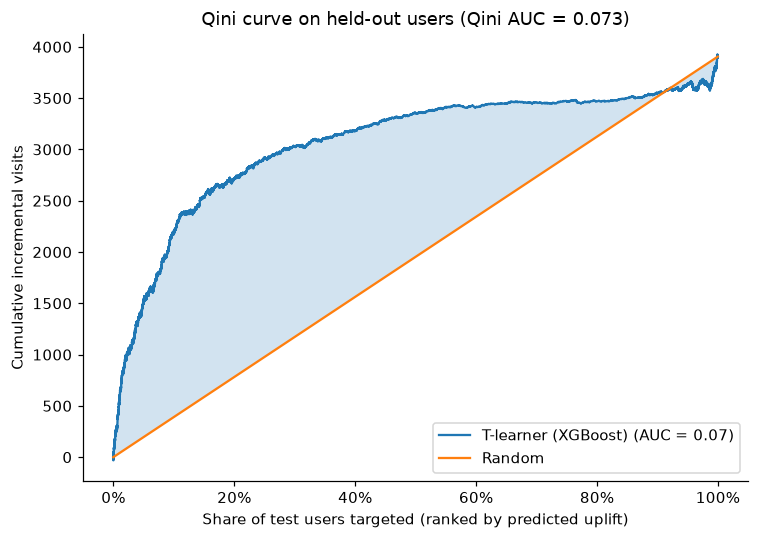

In [26]:
qini_model = qini_auc_score(test["visit"], test_uplift, test["treatment"])
random_scores = np.random.default_rng(42).random(len(test))
qini_random = qini_auc_score(test["visit"], random_scores, test["treatment"])
print(f"Qini AUC: T-learner {qini_model:.4f} vs random scores {qini_random:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
plot_qini_curve(test["visit"], test_uplift, test["treatment"], random=True, perfect=False, ax=ax,
                name="T-learner (XGBoost)")
ax.set_title(f"Qini curve on held-out users (Qini AUC = {qini_model:.3f})")
ax.set_xlabel("Number of test users targeted (ranked by predicted uplift)")
ax.set_ylabel("Cumulative incremental visits")
ax.legend(loc="lower right")
ax.set_xticks(np.linspace(0, len(test), 6), [f"{p:.0%}" for p in np.linspace(0, 1, 6)])
ax.set_xlabel("Share of test users targeted (ranked by predicted uplift)")
fig.tight_layout()
fig.savefig(f"{FIG}/04_qini_curve.png", bbox_inches="tight")
plt.show()

### Targeting: how much of the incremental effect sits in the top X%?
Share captured = incremental visits in the targeted group / incremental visits if we targeted everyone.
Random targeting captures X% of the effect with X% of the users.

The first table uses the standard Qini count (raw treated vs. control). The second answers the same question with the
**Lin-adjusted** ITT in each group, consistent with our headline estimate, so the Step 5 imbalance doesn't inflate
the counts.

In [27]:
tt = uplift.targeting_table(test["visit"], test_uplift, test["treatment"])
tt_adj = uplift.adjusted_targeting_table(test, test_uplift, "visit", FEATURES)
pd.DataFrame({
    "users targeted": tt["users targeted"].map("{:,}".format),
    "share captured (Qini)": tt["share of incremental captured"].map("{:.1%}".format),
    "lift over random (Qini)": tt["lift over random"].map("{:.1f}x".format),
    "adjusted ITT in group (pp)": tt_adj["adjusted ITT in group (pp)"].map("{:.2f}".format),
    "share captured (adjusted)": tt_adj["adjusted share of incremental captured"].map("{:.1%}".format),
    "random targeting": tt["random targeting share"].map("{:.0%}".format),
}).rename(index="{:.0%}".format).rename_axis("target top")

,users targeted,share captured (Qini),lift over random (Qini),adjusted ITT in group (pp),share captured (adjusted),random targeting
target top,,,,,,
10%,"41,939",56.2%,5.6x,5.09,65.8%,10%
20%,"83,878",69.6%,3.5x,2.98,76.9%,20%
30%,"125,816",77.6%,2.6x,2.11,81.7%,30%


**How to read this.** Effects are highly concentrated. A small slice of users accounts for most of the incremental
visits, and most users barely respond to ads (median predicted uplift is close to zero). The adjusted shares come out a
bit higher than the raw Qini shares because the overall total shrinks once the imbalance is removed, while the
top-ranked group's effect stays large.

**Caveats.** These come from one train/test split; the exact shares would move somewhat with a different seed. The
features are anonymized, so we can say *how concentrated* the effect is but not *who* these users are in business
terms. And a T-learner can be noisy because each model is fit separately; the held-out Qini evaluation is what tells
us its ranking is genuinely better than random.

In [28]:
for f in tt.index:
    print(f"Top {f:.0%}: {tt.loc[f, 'share of incremental captured']:.1%} of incremental visits (Qini), "
          f"{tt_adj.loc[f, 'adjusted share of incremental captured']:.1%} (Lin-adjusted); random = {f:.0%}")

Top 10%: 56.2% of incremental visits (Qini), 65.8% (Lin-adjusted); random = 10%
Top 20%: 69.6% of incremental visits (Qini), 76.9% (Lin-adjusted); random = 20%
Top 30%: 77.6% of incremental visits (Qini), 81.7% (Lin-adjusted); random = 30%


### Stability across random seeds
The shares above come from one train/test split and one set of XGBoost random draws. To make sure the numbers we
quote aren't a lucky (or unlucky) split, we refit the whole pipeline with 5 seeds (42–46). Each seed changes both
the train/test split and the XGBoost randomness. We report the **mean and range**; the memo quotes these.

In [29]:
stab = uplift.seed_stability(df, FEATURES, "visit", seeds=(42, 43, 44, 45, 46))
cols = ["qini_auc"] + [f"top{k}_{kind}" for kind in ("qini", "adjusted") for k in (10, 20, 30)]
stab_display = stab[cols].copy()
stab_display.loc["mean"] = stab[cols].mean()
stab_display.loc["min"] = stab[cols].min()
stab_display.loc["max"] = stab[cols].max()
stab_display.style.format({c: "{:.4f}" if c == "qini_auc" else "{:.1%}" for c in cols})

,qini_auc,top10_qini,top20_qini,top30_qini,top10_adjusted,top20_adjusted,top30_adjusted
seed,,,,,,,
42,0.0734,56.2%,69.6%,77.6%,65.8%,76.9%,81.7%
43,0.0762,57.6%,75.5%,80.6%,71.7%,82.6%,82.1%
44,0.0728,57.7%,71.4%,79.7%,69.5%,80.0%,82.7%
45,0.0702,50.7%,68.6%,78.1%,58.5%,73.7%,79.0%
46,0.0751,54.8%,76.2%,85.0%,64.7%,82.3%,86.9%
mean,0.0735,55.4%,72.3%,80.2%,66.0%,79.1%,82.5%
min,0.0702,50.7%,68.6%,77.6%,58.5%,73.7%,79.0%
max,0.0762,57.7%,76.2%,85.0%,71.7%,82.6%,86.9%


In [30]:
summary = pd.DataFrame({
    "share captured, Qini (mean)": [stab[f"top{k}_qini"].mean() for k in (10, 20, 30)],
    "Qini range across seeds": [f"[{stab[f'top{k}_qini'].min():.1%}, {stab[f'top{k}_qini'].max():.1%}]" for k in (10, 20, 30)],
    "share captured, adjusted (mean)": [stab[f"top{k}_adjusted"].mean() for k in (10, 20, 30)],
    "adjusted range across seeds": [f"[{stab[f'top{k}_adjusted'].min():.1%}, {stab[f'top{k}_adjusted'].max():.1%}]" for k in (10, 20, 30)],
    "random targeting": [0.1, 0.2, 0.3],
}, index=["top 10%", "top 20%", "top 30%"])
print(f"Qini AUC across seeds: mean {stab['qini_auc'].mean():.4f}, range [{stab['qini_auc'].min():.4f}, {stab['qini_auc'].max():.4f}]")
summary.style.format({"share captured, Qini (mean)": "{:.1%}", "share captured, adjusted (mean)": "{:.1%}",
                      "random targeting": "{:.0%}"})

Qini AUC across seeds: mean 0.0735, range [0.0702, 0.0762]


,"share captured, Qini (mean)",Qini range across seeds,"share captured, adjusted (mean)",adjusted range across seeds,random targeting
top 10%,55.4%,"[50.7%, 57.7%]",66.0%,"[58.5%, 71.7%]",10%
top 20%,72.3%,"[68.6%, 76.2%]",79.1%,"[73.7%, 82.6%]",20%
top 30%,80.2%,"[77.6%, 85.0%]",82.5%,"[79.0%, 86.9%]",30%


**Reading it.** Every seed's model beats random targeting by a wide margin at every cutoff, and the Qini AUC barely
moves across seeds. The targeting shares move a few points from split to split, which is why the memo quotes the
5-seed mean with its range rather than a single split. Seed 42, used for the curve above, sits on the low side for
the top 20% and 30%.

## Step 8: Segment analysis with multiple-testing correction

Product teams love slicing results by segment ("does it work for new users? for mobile?"). The danger: **every extra
test is another chance for a false positive.** At α = 0.05, if ads truly did nothing, testing 8 segments gives a
1 − 0.95⁸ ≈ **34%** chance that at least one looks "significant" by luck alone. Report that segment as a finding and
you've shipped a false discovery.

**Setup.** We bucket the two features with the most spread, `f0` and `f6`, into quantiles. Both have a value shared by
about 26% of users, so quintile edges collide and each feature ends up with **4 buckets** (8 segments total). Within each
segment we estimate the **Lin-adjusted** effect on visits, consistent with the headline. Two questions per segment:
1. Is the effect in this segment different from **zero**?
2. Is this segment's effect different from the **overall** effect? (This is the heterogeneity question, and the one
   where false discoveries tend to hide.)

**Corrections** (`statsmodels.stats.multitest.multipletests`):
- **Holm:** controls the *family-wise error rate*, P(any false positive) ≤ 5%. Conservative; good when a single false
  claim is costly.
- **Benjamini–Hochberg (BH):** controls the *false discovery rate*, i.e. on average ≤ 5% of "significant" segments are
  false. Less conservative; standard when screening many segments.

In [31]:
from src import segments

seg = segments.segment_effects(df, ["f0", "f6"], FEATURES, outcome="visit", q=5)
c0 = segments.correct(seg["p_value"])
c1 = segments.correct(seg["p_diff_overall"])
overall_lin = adj["visit"].loc["adjusted (Lin, interacted)", "coef"]

seg_table = pd.DataFrame({
    "segment": seg["segment"],
    "users": seg["n"].map("{:,}".format),
    "raw lift (pp)": (seg["raw_lift"] * 100).map("{:.2f}".format),
    "adj. lift (pp)": (seg["adj_lift"] * 100).map("{:.2f}".format),
    "95% CI (pp)": [f"[{lo*100:.2f}, {hi*100:.2f}]" for lo, hi in zip(seg["ci_low"], seg["ci_high"])],
    "rel. lift": seg["rel_lift"].map("{:+.1%}".format),
    "p (≠0) raw": c0["p_raw"].map("{:.2g}".format),
    "p (≠0) Holm": c0["p_holm"].map("{:.2g}".format),
    "p (≠0) BH": c0["p_bh"].map("{:.2g}".format),
    "p (≠overall) raw": c1["p_raw"].map("{:.2g}".format),
    "p (≠overall) Holm": c1["p_holm"].map("{:.2g}".format),
    "p (≠overall) BH": c1["p_bh"].map("{:.2g}".format),
})
print(f"Overall Lin-adjusted visit effect: {overall_lin*100:.3f} pp")
seg_table

Overall Lin-adjusted visit effect: 0.812 pp


,segment,users,raw lift (pp),adj. lift (pp),95% CI (pp),rel. lift,p (≠0) raw,p (≠0) Holm,p (≠0) BH,p (≠overall) raw,p (≠overall) Holm,p (≠overall) BH
0,"f0 (12.62, 18.14]","559,184",2.03,1.50,"[1.33, 1.67]",+21.8%,3.9e-68,2.7e-67,1.6e-67,1e-15,4.1e-15,1.7e-15
1,"f0 (18.14, 22.77]","279,591",0.86,0.63,"[0.46, 0.80]",+17.4%,5.4e-13,3.2e-12,1.4e-12,0.041,0.041,0.041
2,"f0 (22.77, 24.84]","279,592",0.28,0.27,"[0.16, 0.38]",+17.2%,2.3e-06,9.3e-06,3.7e-06,3.1e-21,1.5e-20,6.1e-21
3,"f0 (24.84, 26.75]","279,592",0.05,0.06,"[-0.04, 0.16]",+4.9%,0.24,0.24,0.24,2.2e-51,1.7e-50,1.7e-50
4,"f6 (-29.31, -7.82]","290,968",3.71,2.65,"[2.39, 2.90]",+33.8%,1.3e-93,1e-92,1e-92,6.1e-46,3.6e-45,1.6e-45
5,"f6 (-7.82, -3.99]","310,035",0.59,0.46,"[0.31, 0.61]",+15.8%,7.3e-10,3.7e-09,1.5e-09,2.6e-06,5.2e-06,3e-06
6,"f6 (-3.99, -1.29]","426,546",0.21,0.18,"[0.09, 0.26]",+13.2%,3.8e-05,0.00011,5.1e-05,4.3e-48,3e-47,1.7e-47
7,"f6 (-1.29, 0.29]","370,410",0.24,0.28,"[0.11, 0.46]",+5.5%,0.0017,0.0033,0.0019,2.9e-09,8.6e-09,3.8e-09


In [32]:
print("Effect ≠ 0:       significant raw / Holm / BH =", int(c0["sig_raw"].sum()), "/", int(c0["sig_holm"].sum()), "/", int(c0["sig_bh"].sum()), "of", len(seg))
print("Effect ≠ overall: significant raw / Holm / BH =", int(c1["sig_raw"].sum()), "/", int(c1["sig_holm"].sum()), "/", int(c1["sig_bh"].sum()), "of", len(seg))
changed = seg.loc[c0["sig_raw"] != c0["sig_holm"], "segment"].tolist() + seg.loc[c1["sig_raw"] != c1["sig_holm"], "segment"].tolist()
print("Segments whose conclusion changes after Holm:", changed or "none")

Effect ≠ 0:       significant raw / Holm / BH = 7 / 7 / 7 of 8
Effect ≠ overall: significant raw / Holm / BH = 8 / 8 / 8 of 8
Segments whose conclusion changes after Holm: none


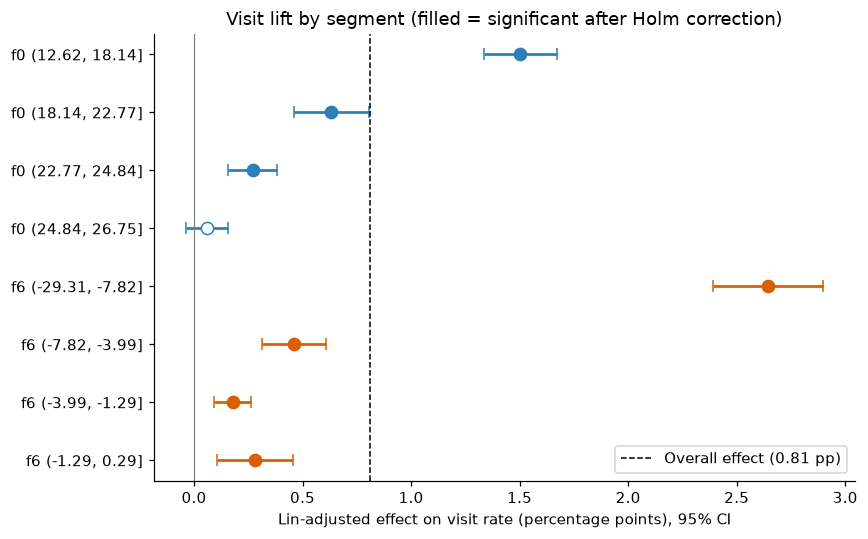

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(seg))[::-1]
colors = np.where(seg["feature"] == "f0", "#2c7fb8", "#d95f02")
for yi, (_, r), col, sig in zip(y, seg.iterrows(), colors, c0["sig_holm"]):
    ax.errorbar(r["adj_lift"] * 100, yi, xerr=[[(r["adj_lift"] - r["ci_low"]) * 100], [(r["ci_high"] - r["adj_lift"]) * 100]],
                fmt="o", color=col, mfc=col if sig else "white", ms=8, capsize=4, lw=1.8)
ax.axvline(overall_lin * 100, color="black", ls="--", lw=1, label=f"Overall effect ({overall_lin*100:.2f} pp)")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(y, seg["segment"])
ax.set_xlabel("Lin-adjusted effect on visit rate (percentage points), 95% CI")
ax.set_title("Visit lift by segment (filled = significant after Holm correction)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(f"{FIG}/05_segment_lifts.png", bbox_inches="tight")
plt.show()

**Reading it.**
- The effect is strongly **heterogeneous**: it's concentrated among users with low `f0` and very negative `f6`, and
  close to zero in the top `f0` bucket. That matches the uplift model: a minority of users carries most of the effect.
- With 1.4M users and large differences, the p-values are so small that Holm and BH change almost nothing here.
  That's specific to this dataset's size. With smaller segments, more cuts, or subtler effects, results near
  p = 0.05 routinely flip after correction, which is exactly the false-discovery risk the correction exists for.
- The cleanest habit is to **pre-register** the few segments you care about, report raw *and* corrected p-values, and
  treat anything found by slicing as a hypothesis for the next test rather than a result.
- Segment estimates here are descriptive, not prescriptive: the features are anonymized, and the buckets are on
  single features, while the uplift model uses all features jointly.